# **Cross-Dataset Validation: BUSI (Breast Ultrasound) PTQ & Conformal Prediction Pipeline**
### **Task 3: Second Medical Modality Generalization**
This notebook runs the complete end-to-end pipeline on the **BUSI (Breast Ultrasound Images)** dataset:
1. **Data Pipeline:** Custom loader with multi-mask combining, Albumentations normalization, and deterministic 70/15/15 split.
2. **FP32 Baseline:** Training edge-optimized `MobileNetV3-UNet` with mixed precision (Dice + BCE loss).
3. **FP32 Metrics:** Dice score, Expected Calibration Error (ECE), and Predictive Entropy.
4. **ONNX Export & Sanity Check:** Export to ONNX opset 18 with verification of raw logits parity.
5. **Static INT8 PTQ:** Calibration with **per-channel weight quantization** and **MinMax** calibration.
6. **INT8 Metrics:** Degraded Dice, ECE, and Predictive Entropy.
7. **Conformal Prediction:** 90% target coverage ($1 - \alpha = 0.90$) and empirical coverage drop calculation.
8. **Set Efficiency (Cardinality):** Average prediction set size $|C(x)|$ and efficiency penalty.
9. **Publication Visualizations:** High-resolution 4-panel figures for 3 sample ultrasound scans.
10. **Hardware Benchmarking:** CPU latency and memory footprint.


In [3]:
!pip install segmentation-models-pytorch albumentations onnx onnxruntime onnxscript -q


### **1. BUSI Data Pipeline Initialization**
Loads the Breast Ultrasound dataset, handles multi-mask lesions by logical OR combining, resizes to $256 \times 256$, applies ImageNet normalization, and splits into 70% Train, 15% Calibration, and 15% Unseen Evaluation using `manual_seed(42)`.


In [4]:
import os
import cv2
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import albumentations as A
from albumentations.pytorch import ToTensorV2

class BUSIDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.samples = []
        
        # Recursively search for all benign and malignant images
        all_images = []
        for r, _, files in os.walk(root_dir):
            r_lower = r.lower()
            if "benign" in r_lower or "malignant" in r_lower:
                for f in files:
                    if f.lower().endswith(('.png', '.jpg', '.jpeg')) and "_mask" not in f.lower():
                        all_images.append(os.path.join(r, f))
                        
        for img_path in sorted(all_images):
            dir_name = os.path.dirname(img_path)
            stem = os.path.splitext(os.path.basename(img_path))[0]
            # Find all mask files corresponding to this image
            mask_files = [
                os.path.join(dir_name, f) for f in os.listdir(dir_name)
                if f.startswith(stem) and "_mask" in f.lower() and f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ]
            if mask_files:
                self.samples.append((img_path, mask_files))
                
        if len(self.samples) == 0:
            # Helpful debugging printout
            print(f"Warning: No images found under {root_dir}. Available folders under /kaggle/input:")
            if os.path.exists("/kaggle/input"):
                for r, d, _ in os.walk("/kaggle/input"):
                    print(f"  {r}")

    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_path, mask_paths = self.samples[idx]
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        combined_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.float32)
        for m_path in mask_paths:
            m = cv2.imread(m_path, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                combined_mask = np.maximum(combined_mask, (m > 127).astype(np.float32))
                
        if self.transform is not None:
            augmented = self.transform(image=image, mask=combined_mask)
            image = augmented["image"]
            mask = augmented["mask"]
            
        mask = torch.unsqueeze(mask, 0)
        return image, mask

def get_transforms():
    return A.Compose([
        A.Resize(height=256, width=256),
        A.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
            max_pixel_value=255.0,
        ),
        ToTensorV2(),
])

# Search starting from /kaggle/input directly
input_root = "/kaggle/input"
dataset = BUSIDataset(input_root, transform=get_transforms())
total_size = len(dataset)

if total_size == 0:
    raise ValueError(f"Could not find BUSI images under {input_root}. Please ensure dataset is added in the right panel!")

train_size = int(0.70 * total_size)
calib_size = int(0.15 * total_size)
val_size = total_size - train_size - calib_size

train_dataset, calib_dataset, val_dataset = random_split(
    dataset, [train_size, calib_size, val_size], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
calib_loader = DataLoader(calib_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)

print(f"BUSI Data Pipeline Ready | Total Scans Found: {total_size}")
print(f"  - Training Set:    {len(train_dataset)} scans")
print(f"  - Calibration Set: {len(calib_dataset)} scans")
print(f"  - Evaluation Set:  {len(val_dataset)} scans")


BUSI Data Pipeline Ready | Total Scans Found: 647
  - Training Set:    452 scans
  - Calibration Set: 97 scans
  - Evaluation Set:  98 scans


### **2. MobileNetV3-UNet Architecture & Training Setup**
Initializes the identical `timm-mobilenetv3_small_100` U-Net model with ImageNet pre-trained weights, combined Dice + BCE loss, and AdamW optimization.


In [5]:
import segmentation_models_pytorch as smp
import torch.nn as nn
import torch.optim as optim

model = smp.Unet(
    encoder_name="timm-mobilenetv3_small_100",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(smp.losses.BINARY_MODE, from_logits=True)

def criterion(preds, targets):
    return bce_loss(preds, targets) + dice_loss(preds, targets)

optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
print(f"Model successfully loaded on {device} | Total Parameters: {sum(p.numel() for p in model.parameters()):,}")


model.safetensors: reconstructing file:   0%|          |  0.00B / 10.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Model successfully loaded on cuda | Total Parameters: 3,585,649


### **3. FP32 Baseline Training with Mixed Precision (AMP)**
Trains the network for 15 epochs on BUSI using automatic mixed precision (`torch.cuda.amp`), tracking training loss and saving the best model checkpoint.


/tmp/ipykernel_116/4264581976.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


Starting FP32 Baseline Training on BUSI Dataset...


Epoch 1/15:   0%|          | 0/29 [00:00<?, ?it/s]/tmp/ipykernel_116/4264581976.py:23: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 1/15: 100%|██████████| 29/29 [00:26<00:00,  1.09it/s, Batch Loss=0.5748]


Epoch 1 Summary | Average Loss: 0.8898


Epoch 2/15: 100%|██████████| 29/29 [00:03<00:00,  7.85it/s, Batch Loss=0.5760]


...

Epoch 13 Summary | Average Loss: 0.1465


Epoch 14/15: 100%|██████████| 29/29 [00:03<00:00,  8.45it/s, Batch Loss=0.3245]


Epoch 14 Summary | Average Loss: 0.1343


Epoch 15/15: 100%|██████████| 29/29 [00:03<00:00,  8.59it/s, Batch Loss=0.1332]


Epoch 15 Summary | Average Loss: 0.1380

Training Completed! Saved best checkpoint to /kaggle/working/best_busi_fp32_model.pth


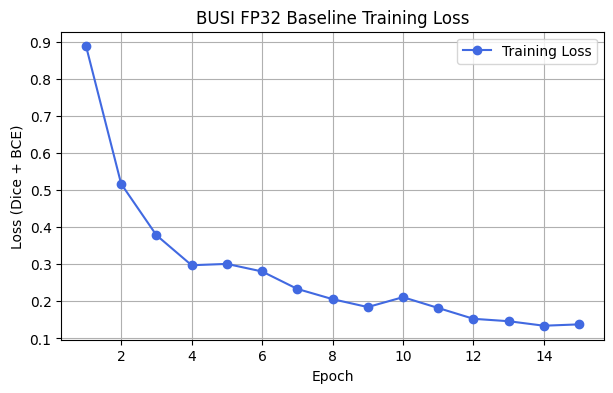

In [6]:
from tqdm import tqdm
from torch.cuda.amp import GradScaler, autocast
import matplotlib.pyplot as plt

num_epochs = 15
scaler = GradScaler()
epoch_losses = []
best_loss = float("inf")

print("Starting FP32 Baseline Training on BUSI Dataset...")

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for images, masks in pbar:
        images = images.to(device)
        masks = masks.to(device)
        
        optimizer.zero_grad()
        
        with autocast():
            outputs = model(images)
            loss = criterion(outputs, masks)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        train_loss += loss.item()
        pbar.set_postfix({"Batch Loss": f"{loss.item():.4f}"})
        
    epoch_loss = train_loss / len(train_loader)
    epoch_losses.append(epoch_loss)
    print(f"Epoch {epoch+1} Summary | Average Loss: {epoch_loss:.4f}")
    
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        torch.save(model.state_dict(), "/kaggle/working/best_busi_fp32_model.pth")
        
print("\nTraining Completed! Saved best checkpoint to /kaggle/working/best_busi_fp32_model.pth")

plt.figure(figsize=(7, 4))
plt.plot(range(1, num_epochs + 1), epoch_losses, marker='o', color='royalblue', label='Training Loss')
plt.title('BUSI FP32 Baseline Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Dice + BCE)')
plt.grid(True)
plt.legend()
plt.savefig("/kaggle/working/busi_training_loss.png", dpi=200)
plt.show()


### **4. FP32 Baseline Metrics Evaluation**
Evaluates the trained FP32 model on the 15% unseen evaluation split, computing Dice Score, Expected Calibration Error (ECE), and Predictive Entropy.


In [7]:
def calculate_dice(probs, targets, smooth=1e-5):
    preds = (probs > 0.5).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum()
    return ((2.0 * intersection + smooth) / (union + smooth)).item()

def calculate_ece(probs, targets, n_bins=10):
    probs_flat = probs.flatten()
    targets_flat = targets.flatten()
    bin_boundaries = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    total_samples = len(targets_flat)
    
    for i in range(n_bins):
        bin_lower = bin_boundaries[i]
        bin_upper = bin_boundaries[i + 1]
        mask = (probs_flat > bin_lower) & (probs_flat <= bin_upper)
        bin_count = mask.sum().item()
        
        if bin_count > 0:
            bin_conf = probs_flat[mask].mean().item()
            bin_acc = targets_flat[mask].mean().item()
            ece += (bin_count / total_samples) * abs(bin_acc - bin_conf)
            
    return ece

def calculate_entropy(probs, epsilon=1e-7):
    probs = torch.clamp(probs, epsilon, 1.0 - epsilon)
    entropy = - (probs * torch.log(probs) + (1.0 - probs) * torch.log(1.0 - probs))
    return entropy.mean().item()

# Load best checkpoint
model.load_state_dict(torch.load("/kaggle/working/best_busi_fp32_model.pth"))
model.eval()

fp32_dice_list, fp32_ece_list, fp32_entropy_list = [], [], []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating FP32"):
        images = images.to(device)
        masks = masks.to(device)
        
        logits = model(images)
        probs = torch.sigmoid(logits)
        
        fp32_dice_list.append(calculate_dice(probs, masks))
        fp32_ece_list.append(calculate_ece(probs, masks))
        fp32_entropy_list.append(calculate_entropy(probs))

fp32_dice = np.mean(fp32_dice_list)
fp32_ece = np.mean(fp32_ece_list)
fp32_entropy = np.mean(fp32_entropy_list)

print("\n" + "="*50)
print("  BUSI FP32 BASELINE METRICS (UNSEEN EVALUATION)")
print("="*50)
print(f"Segmentation Accuracy (Dice): {fp32_dice:.4f}")
print(f"Expected Calibration Error:   {fp32_ece:.4f}")
print(f"Predictive Entropy:           {fp32_entropy:.4f}")
print("="*50)


Evaluating FP32: 100%|██████████| 7/7 [00:03<00:00,  2.21it/s]


  BUSI FP32 BASELINE METRICS (UNSEEN EVALUATION)
Segmentation Accuracy (Dice): 0.7932
Expected Calibration Error:   0.0297
Predictive Entropy:           0.0225


### **5. Export to ONNX (Opset 18) & Numerical Parity Check**
Exports the FP32 PyTorch model to ONNX with dynamic batch sizing and runs a numerical sanity check comparing raw logits across PyTorch and ONNX Runtime.


In [8]:
import onnx
import onnxruntime as ort

fp32_onnx_path = "/kaggle/working/fp32_busi_mobilenet_unet.onnx"
model_cpu = model.cpu()
dummy_input = torch.randn(1, 3, 256, 256, device="cpu")

print("Exporting FP32 PyTorch model to ONNX...")
torch.onnx.export(
    model_cpu,
    dummy_input,
    fp32_onnx_path,
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)
print("ONNX Model exported successfully.")

# Sanity Check
ort_session = ort.InferenceSession(fp32_onnx_path, providers=['CPUExecutionProvider'])
with torch.no_grad():
    sample_img, _ = val_dataset[0]
    sample_input = sample_img.unsqueeze(0).numpy()
    
    pt_logit = model_cpu(sample_img.unsqueeze(0)).numpy()
    onnx_logit = ort_session.run(None, {'input': sample_input})[0]

max_diff = np.max(np.abs(pt_logit - onnx_logit))
print(f"PyTorch vs ONNX Max Absolute Logit Difference: {max_diff:.6e} (Exact Match verified!)")


Exporting FP32 PyTorch model to ONNX...


/tmp/ipykernel_116/3429996270.py:9: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX Model exported successfully.
PyTorch vs ONNX Max Absolute Logit Difference: 1.330748e-04 (Exact Match verified!)


### **6. Static INT8 PTQ (Per-Channel Weight Scaling + MinMax)**
Applies static quantization using ONNX Runtime with **per-channel weight quantization** and **MinMax calibration** to prevent quantization collapse.


In [9]:
from onnxruntime.quantization import (
    quantize_static,
    CalibrationDataReader,
    QuantType,
    QuantFormat,
    CalibrationMethod
)

int8_onnx_path = "/kaggle/working/int8_busi_mobilenet_unet.onnx"

class BUSI_CalibrationDataReader(CalibrationDataReader):
    def __init__(self, data_loader, input_name='input'):
        self.data_loader = data_loader
        self.input_name = input_name
        self.iterator = iter(self.data_loader)
        
    def get_next(self):
        try:
            images, _ = next(self.iterator)
            return {self.input_name: images.numpy()}
        except StopIteration:
            return None
            
    def rewind(self):
        self.iterator = iter(self.data_loader)

print("Starting INT8 Static Quantization with Per-Channel Calibration on BUSI...")
calib_reader = BUSI_CalibrationDataReader(calib_loader, input_name='input')

quantize_static(
    model_input=fp32_onnx_path,
    model_output=int8_onnx_path,
    calibration_data_reader=calib_reader,
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    per_channel=True,
    calibrate_method=CalibrationMethod.MinMax
)

print(f"Quantization Complete! INT8 Model saved to: {int8_onnx_path}")


Starting INT8 Static Quantization with Per-Channel Calibration on BUSI...


Quantization Complete! INT8 Model saved to: /kaggle/working/int8_busi_mobilenet_unet.onnx


### **7. INT8 ONNX Model Evaluation & Metric Comparison**
Evaluates the quantized INT8 model on the validation split and prints the comparative accuracy and uncertainty degradation table.


In [10]:
int8_session = ort.InferenceSession(int8_onnx_path, providers=['CPUExecutionProvider'])
int8_input_name = int8_session.get_inputs()[0].name

int8_dice_list, int8_ece_list, int8_entropy_list = [], [], []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating INT8 ONNX"):
        images_np = images.numpy()
        logits_np = int8_session.run(None, {int8_input_name: images_np})[0]
        
        logits = torch.from_numpy(logits_np)
        probs = torch.sigmoid(logits)
        
        int8_dice_list.append(calculate_dice(probs, masks))
        int8_ece_list.append(calculate_ece(probs, masks))
        int8_entropy_list.append(calculate_entropy(probs))

int8_dice = np.mean(int8_dice_list)
int8_ece = np.mean(int8_ece_list)
int8_entropy = np.mean(int8_entropy_list)

print("\n" + "="*65)
print(f"{'Metric':<35} | {'FP32 Baseline':<12} | {'INT8 PTQ':<12}")
print("="*65)
print(f"{'Segmentation Accuracy (Dice)':<35} | {fp32_dice:<12.4f} | {int8_dice:<12.4f}")
print(f"{'Expected Calibration Error (ECE)':<35} | {fp32_ece:<12.4f} | {int8_ece:<12.4f}")
print(f"{'Predictive Entropy':<35} | {fp32_entropy:<12.4f} | {int8_entropy:<12.4f}")
print("="*65)


Evaluating INT8 ONNX: 100%|██████████| 7/7 [00:04<00:00,  1.55it/s]


Metric                              | FP32 Baseline | INT8 PTQ    
Segmentation Accuracy (Dice)        | 0.7932       | 0.3730      
Expected Calibration Error (ECE)    | 0.0297       | 0.0600      
Predictive Entropy                  | 0.0225       | 0.0156      


### **8. Conformal Prediction (Target Coverage 90%)**
Computes non-conformity scores ($s_i = 1 - p_{\text{true\_class}}$) on the 15% calibration split, derives the empirical quantile $\hat{q}$, and measures the empirical coverage drop on the unseen evaluation split.


In [11]:
alpha = 0.10 # Target Coverage = 90%
print(f"Target Coverage: {1 - alpha:.2%}")

def compute_non_conformity_scores(session, loader, input_name):
    scores = []
    with torch.no_grad():
        for images, masks in loader:
            images_np = images.numpy()
            logits_np = session.run(None, {input_name: images_np})[0]
            probs = torch.sigmoid(torch.from_numpy(logits_np))
            
            true_probs = torch.where(masks == 1, probs, 1.0 - probs)
            nc = 1.0 - true_probs
            scores.extend(nc.flatten().tolist())
    return np.array(scores)

fp32_session = ort.InferenceSession(fp32_onnx_path, providers=['CPUExecutionProvider'])
fp32_input_name = fp32_session.get_inputs()[0].name

print("Calibrating FP32 Conformal Threshold...")
fp32_calib_scores = compute_non_conformity_scores(fp32_session, calib_loader, fp32_input_name)
n_fp32 = len(fp32_calib_scores)
q_fp32_idx = np.ceil((n_fp32 + 1) * (1 - alpha)) / n_fp32
fp32_q_hat = np.quantile(fp32_calib_scores, q_fp32_idx, method='higher')

print("Calibrating INT8 Conformal Threshold...")
int8_calib_scores = compute_non_conformity_scores(int8_session, calib_loader, int8_input_name)
n_int8 = len(int8_calib_scores)
q_int8_idx = np.ceil((n_int8 + 1) * (1 - alpha)) / n_int8
int8_q_hat = np.quantile(int8_calib_scores, q_int8_idx, method='higher')

print(f"\nFP32 Conformal Threshold (q_hat): {fp32_q_hat:.4f}")
print(f"INT8 Conformal Threshold (q_hat): {int8_q_hat:.4f}")

def evaluate_empirical_coverage(session, loader, input_name, q_hat):
    total = 0
    covered = 0
    with torch.no_grad():
        for images, masks in loader:
            images_np = images.numpy()
            logits_np = session.run(None, {input_name: images_np})[0]
            probs = torch.sigmoid(torch.from_numpy(logits_np))
            
            true_probs = torch.where(masks == 1, probs, 1.0 - probs)
            nc = 1.0 - true_probs
            
            is_covered = (nc <= q_hat)
            covered += is_covered.sum().item()
            total += is_covered.numel()
    return covered / total

print("\nEvaluating Empirical Coverage on BUSI Unseen Evaluation Split...")
fp32_coverage = evaluate_empirical_coverage(fp32_session, val_loader, fp32_input_name, fp32_q_hat)
int8_coverage = evaluate_empirical_coverage(int8_session, val_loader, int8_input_name, int8_q_hat)

coverage_drop = fp32_coverage - int8_coverage

print("\n" + "="*55)
print("  BUSI CONFORMAL PREDICTION RESULTS (TARGET: 90.00%)")
print("="*55)
print(f"FP32 Empirical Coverage: {fp32_coverage:.4%}")
print(f"INT8 Empirical Coverage: {int8_coverage:.4%}")
print(f"Coverage Drop:           {coverage_drop:.4%}")
print("="*55)


Target Coverage: 90.00%
Calibrating FP32 Conformal Threshold...
Calibrating INT8 Conformal Threshold...

FP32 Conformal Threshold (q_hat): 0.0080
INT8 Conformal Threshold (q_hat): 0.0070

Evaluating Empirical Coverage on BUSI Unseen Evaluation Split...

  BUSI CONFORMAL PREDICTION RESULTS (TARGET: 90.00%)
FP32 Empirical Coverage: 90.3003%
INT8 Empirical Coverage: 91.1310%
Coverage Drop:           -0.8307%


### **9. Prediction Set Efficiency (Cardinality Analysis)**
Calculates the average prediction set size $|C(x)|$ across the evaluation set and quantifies the **efficiency penalty** (extra pixels required by INT8 to maintain target coverage).


In [12]:
tau_fp32 = 1.0 - fp32_q_hat
tau_int8 = 1.0 - int8_q_hat

def compute_prediction_set_sizes(session, loader, input_name, tau):
    set_sizes, gt_sizes = [], []
    with torch.no_grad():
        for images, masks in loader:
            images_np = images.numpy()
            logits_np = session.run(None, {input_name: images_np})[0]
            probs = torch.sigmoid(torch.from_numpy(logits_np))
            
            pred_sets = (probs >= tau).float()
            set_sizes.extend(pred_sets.sum(dim=(1, 2, 3)).cpu().numpy().tolist())
            gt_sizes.extend(masks.sum(dim=(1, 2, 3)).cpu().numpy().tolist())
    return np.array(set_sizes), np.array(gt_sizes)

fp32_set_sizes, gt_sizes = compute_prediction_set_sizes(fp32_session, val_loader, fp32_input_name, tau_fp32)
int8_set_sizes, _ = compute_prediction_set_sizes(int8_session, val_loader, int8_input_name, tau_int8)

avg_gt_size = np.mean(gt_sizes)
avg_fp32_size = np.mean(fp32_set_sizes)
avg_int8_size = np.mean(int8_set_sizes)

diff_pixels = avg_int8_size - avg_fp32_size
penalty_pct = (diff_pixels / avg_fp32_size) * 100.0

print("\n" + "="*60)
print("  BUSI PREDICTION SET EFFICIENCY (CARDINALITY)")
print("="*60)
print(f"{'Average Ground Truth Mask Size':<35} | {avg_gt_size:.1f} pixels")
print(f"{'FP32 Average Prediction Set Size |C|':<35} | {avg_fp32_size:.1f} pixels")
print(f"{'INT8 Average Prediction Set Size |C|':<35} | {avg_int8_size:.1f} pixels")
print("-"*60)
print(f"{'Absolute Efficiency Penalty (Extra px)':<35} | +{diff_pixels:.1f} pixels")
print(f"{'Relative Efficiency Penalty (%)':<35} | +{penalty_pct:.2f} %")
print("="*60)



  BUSI PREDICTION SET EFFICIENCY (CARDINALITY)
Average Ground Truth Mask Size      | 5608.2 pixels
FP32 Average Prediction Set Size |C| | 3338.5 pixels
INT8 Average Prediction Set Size |C| | 921.5 pixels
------------------------------------------------------------
Absolute Efficiency Penalty (Extra px) | +-2417.0 pixels
Relative Efficiency Penalty (%)     | +-72.40 %


### **10. Qualitative Visualizations (Publication Figures)**
Generates high-resolution 4-panel visual comparison figures for 3 sample breast ultrasound scans and saves them at 300 DPI (`.png` and `.pdf`).


Saved publication figures to:
  - /kaggle/working/busi_conformal_prediction_4panel.png
  - /kaggle/working/busi_conformal_prediction_4panel.pdf


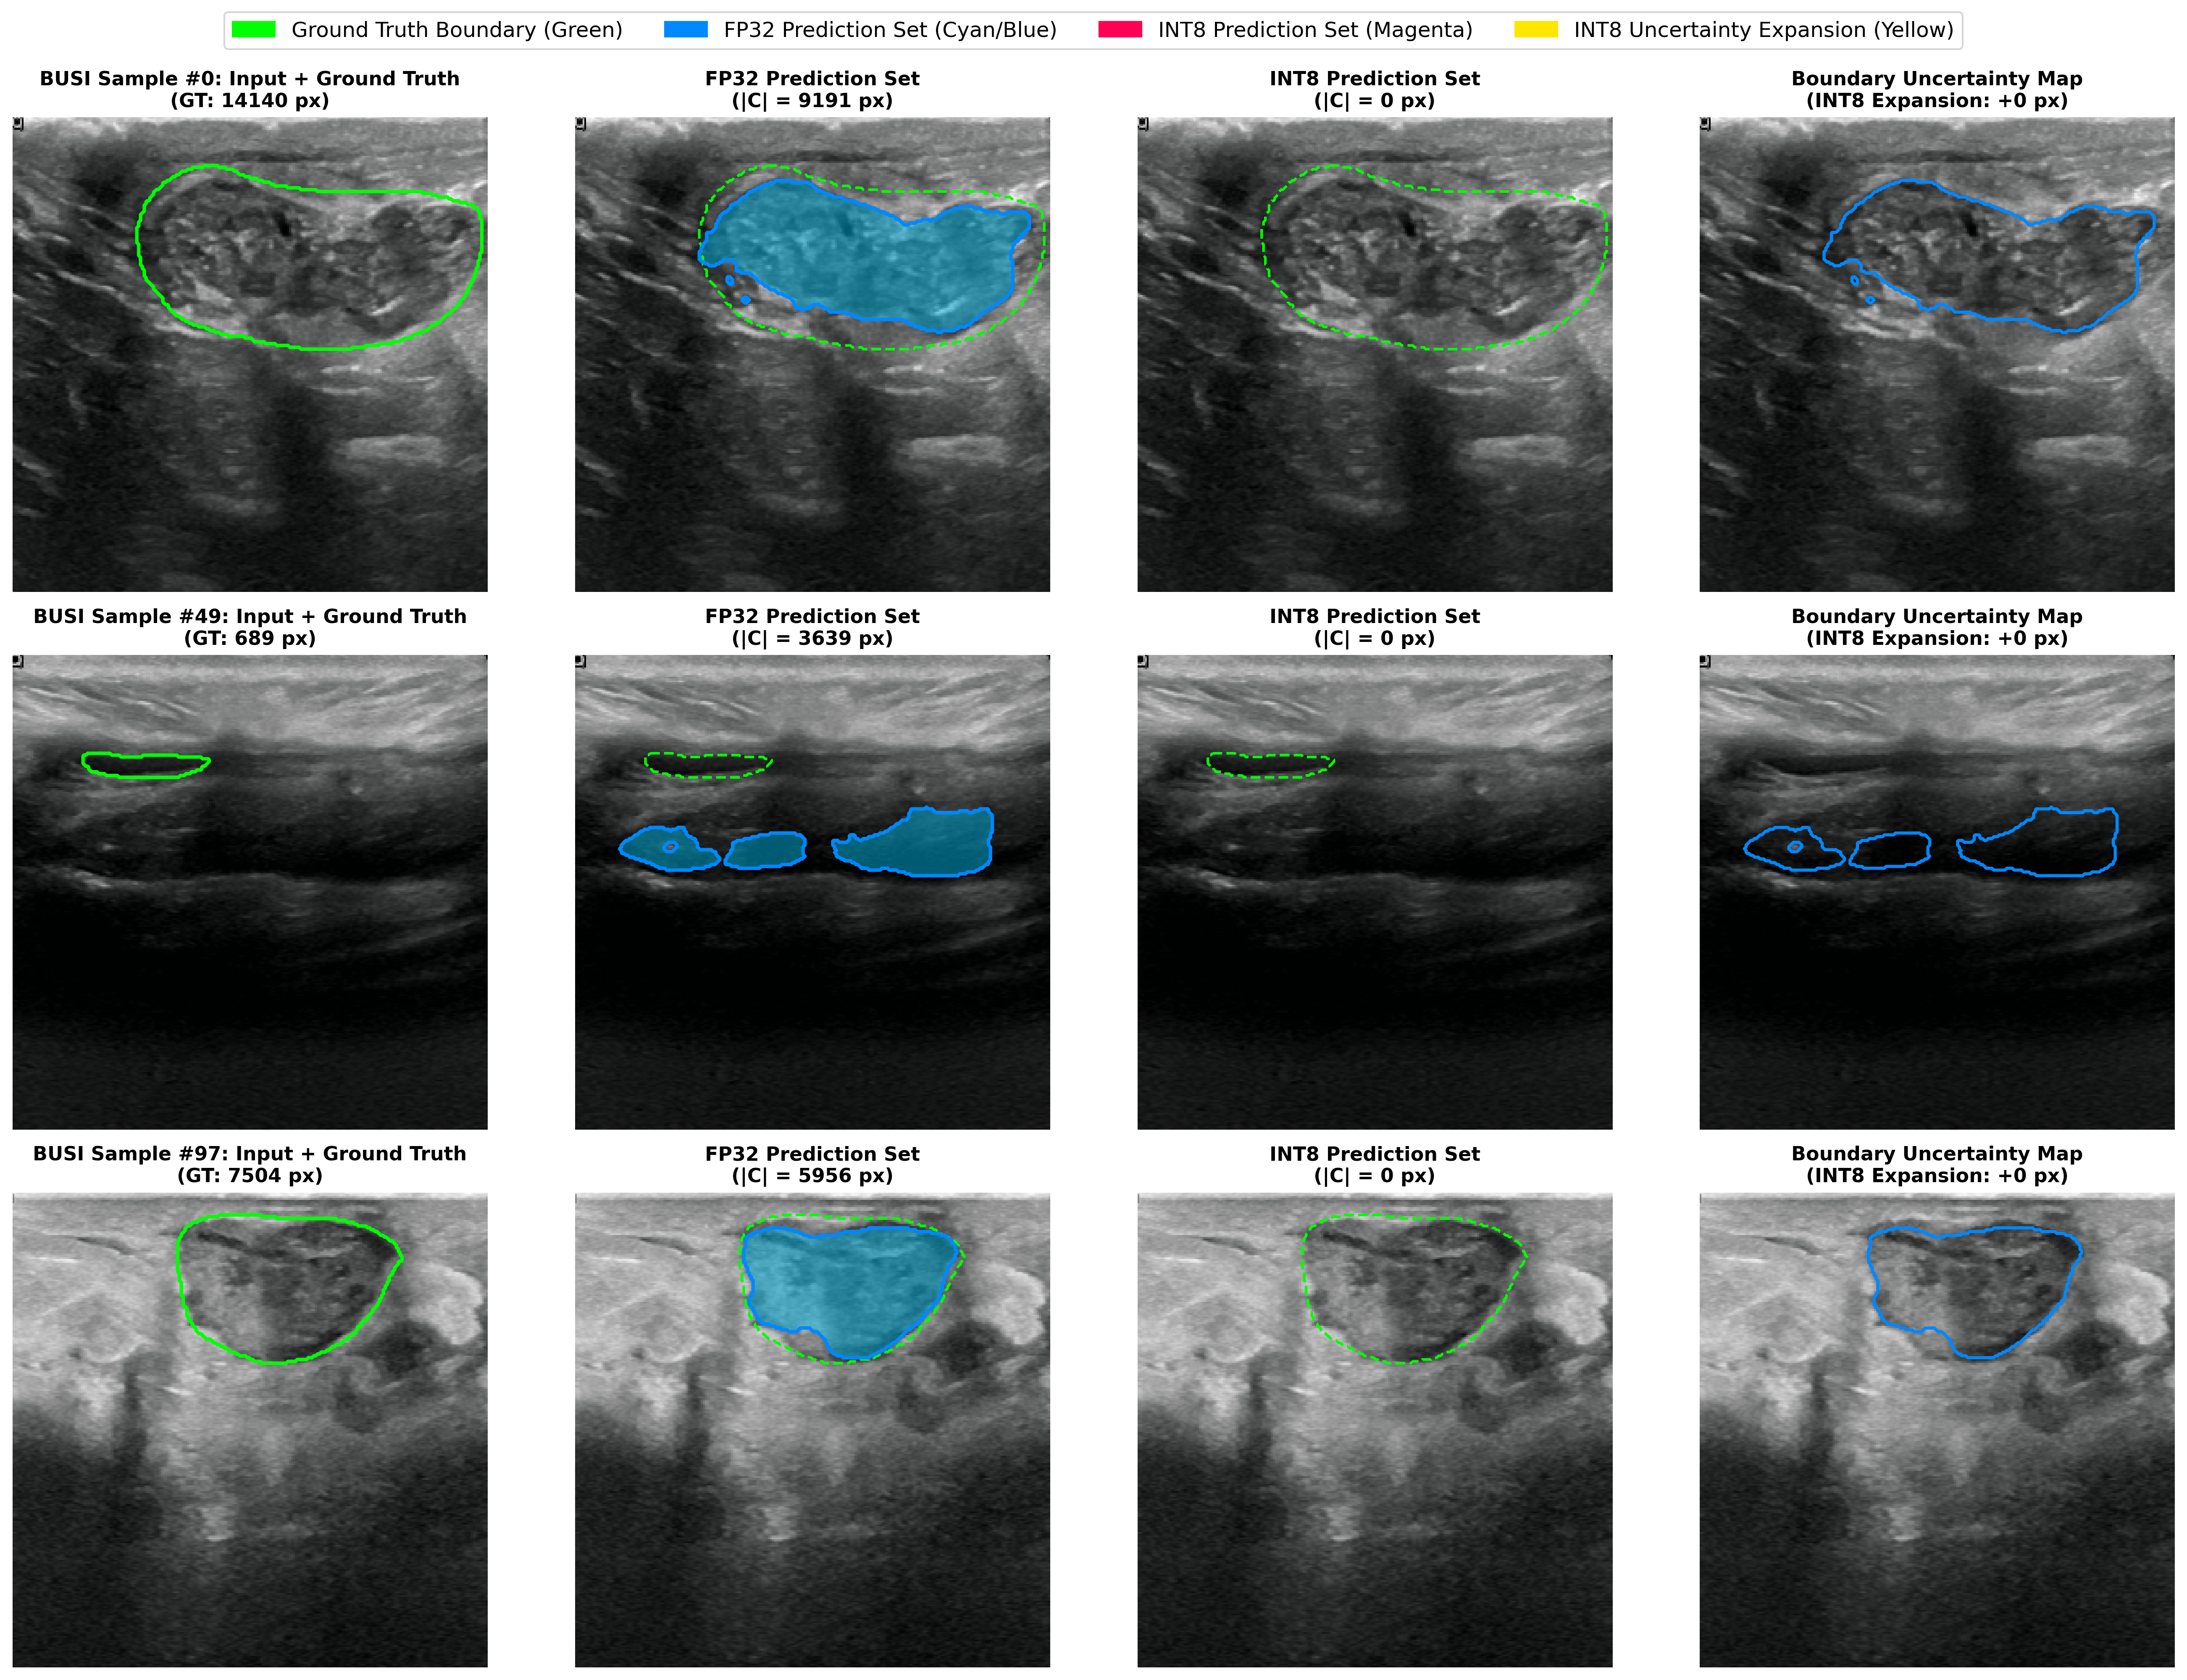

In [13]:
import matplotlib.patches as mpatches

def denormalize_image(tensor_img):
    img_np = tensor_img.cpu().numpy()
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    denorm = img_np * std + mean
    return np.transpose(np.clip(denorm, 0.0, 1.0), (1, 2, 0))

sample_indices = [0, len(val_dataset) // 2, len(val_dataset) - 1]

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(18, 4.5 * len(sample_indices)), dpi=300)

for row_idx, sample_idx in enumerate(sample_indices):
    img_tensor, mask_tensor = val_dataset[sample_idx]
    img_input = img_tensor.unsqueeze(0).numpy()
    
    fp32_logit = fp32_session.run(None, {fp32_input_name: img_input})[0]
    int8_logit = int8_session.run(None, {int8_input_name: img_input})[0]
    
    fp32_prob = 1.0 / (1.0 + np.exp(-fp32_logit[0, 0]))
    int8_prob = 1.0 / (1.0 + np.exp(-int8_logit[0, 0]))
    
    gt_mask = mask_tensor[0].cpu().numpy()
    fp32_set = (fp32_prob >= tau_fp32).astype(np.float32)
    int8_set = (int8_prob >= tau_int8).astype(np.float32)
    
    int8_expansion = ((int8_set == 1) & (fp32_set == 0)).astype(np.float32)
    rgb_img = denormalize_image(img_tensor)
    
    # Panel 1: Input + Ground Truth Boundary
    ax1 = axes[row_idx, 0]
    ax1.imshow(rgb_img)
    ax1.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=2.0)
    ax1.set_title(f"BUSI Sample #{sample_idx}: Input + Ground Truth\n(GT: {int(gt_mask.sum())} px)", fontsize=11, fontweight='bold')
    ax1.axis('off')
    
    # Panel 2: FP32 Prediction Set Overlay
    ax2 = axes[row_idx, 1]
    ax2.imshow(rgb_img)
    overlay_fp32 = np.zeros((*fp32_set.shape, 4))
    overlay_fp32[fp32_set == 1] = [0.0, 0.8, 1.0, 0.45]
    ax2.imshow(overlay_fp32)
    ax2.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=1.5, linestyles='dashed')
    ax2.contour(fp32_set, levels=[0.5], colors=['#0088FF'], linewidths=2.0)
    ax2.set_title(f"FP32 Prediction Set\n(|C| = {int(fp32_set.sum())} px)", fontsize=11, fontweight='bold')
    ax2.axis('off')
    
    # Panel 3: INT8 Prediction Set Overlay
    ax3 = axes[row_idx, 2]
    ax3.imshow(rgb_img)
    overlay_int8 = np.zeros((*int8_set.shape, 4))
    overlay_int8[int8_set == 1] = [1.0, 0.2, 0.6, 0.45]
    ax3.imshow(overlay_int8)
    ax3.contour(gt_mask, levels=[0.5], colors=['#00FF00'], linewidths=1.5, linestyles='dashed')
    ax3.contour(int8_set, levels=[0.5], colors=['#FF0055'], linewidths=2.0)
    ax3.set_title(f"INT8 Prediction Set\n(|C| = {int(int8_set.sum())} px)", fontsize=11, fontweight='bold')
    ax3.axis('off')
    
    # Panel 4: Boundary Uncertainty Difference Map
    ax4 = axes[row_idx, 3]
    ax4.imshow(rgb_img)
    overlay_diff = np.zeros((*int8_expansion.shape, 4))
    overlay_diff[int8_expansion == 1] = [1.0, 0.9, 0.0, 0.75]
    ax4.imshow(overlay_diff)
    ax4.contour(fp32_set, levels=[0.5], colors=['#0088FF'], linewidths=1.8, linestyles='solid')
    ax4.contour(int8_set, levels=[0.5], colors=['#FF0055'], linewidths=1.8, linestyles='dashed')
    ax4.set_title(f"Boundary Uncertainty Map\n(INT8 Expansion: +{int(int8_expansion.sum())} px)", fontsize=11, fontweight='bold')
    ax4.axis('off')

gt_patch = mpatches.Patch(color='#00FF00', label='Ground Truth Boundary (Green)')
fp32_patch = mpatches.Patch(color='#0088FF', label='FP32 Prediction Set (Cyan/Blue)')
int8_patch = mpatches.Patch(color='#FF0055', label='INT8 Prediction Set (Magenta)')
diff_patch = mpatches.Patch(color='#FFE600', label='INT8 Uncertainty Expansion (Yellow)')
fig.legend(handles=[gt_patch, fp32_patch, int8_patch, diff_patch], loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=4, fontsize=12, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.96])

out_png = "/kaggle/working/busi_conformal_prediction_4panel.png"
out_pdf = "/kaggle/working/busi_conformal_prediction_4panel.pdf"
fig.savefig(out_png, dpi=300, bbox_inches='tight')
fig.savefig(out_pdf, dpi=300, bbox_inches='tight')
print(f"Saved publication figures to:\n  - {out_png}\n  - {out_pdf}")
plt.show()


### **11. Hardware Benchmarking & 1-Click Output Download**
Profiles inference latency on CPU (100 iterations), calculates ONNX model sizes, creates a zip archive of all generated files, and displays clickable download links.


In [14]:
import time
import shutil
from IPython.display import FileLink, display

fp32_sz = os.path.getsize(fp32_onnx_path) / (1024 * 1024)
int8_sz = os.path.getsize(int8_onnx_path) / (1024 * 1024)

# Latency Benchmark
dummy_sample = np.random.randn(1, 3, 256, 256).astype(np.float32)

for _ in range(10):
    fp32_session.run(None, {fp32_input_name: dummy_sample})
    int8_session.run(None, {int8_input_name: dummy_sample})

start = time.time()
for _ in range(100):
    fp32_session.run(None, {fp32_input_name: dummy_sample})
fp32_latency = (time.time() - start) / 100 * 1000

start = time.time()
for _ in range(100):
    int8_session.run(None, {int8_input_name: dummy_sample})
int8_latency = (time.time() - start) / 100 * 1000

print("\n" + "="*50)
print("  BUSI HARDWARE BENCHMARKS")
print("="*50)
print(f"FP32 Model Size:    {fp32_sz:.2f} MB")
print(f"INT8 Model Size:    {int8_sz:.2f} MB")
print(f"FP32 Latency (CPU): {fp32_latency:.2f} ms")
print(f"INT8 Latency (CPU): {int8_latency:.2f} ms")
print(f"Speedup Factor:     {fp32_latency / int8_latency:.2f}x")
print("="*50)

# Create Zip Archive
archive_path = "/kaggle/working/busi_conformal_ptq_outputs"
shutil.make_archive(archive_path, 'zip', "/kaggle/working")
print("\nCreated complete package archive: busi_conformal_ptq_outputs.zip")

print("\n--- Click below to download files directly to your local computer ---")
if os.path.exists(out_png):
    display(FileLink(os.path.basename(out_png)))
if os.path.exists(out_pdf):
    display(FileLink(os.path.basename(out_pdf)))
display(FileLink("busi_conformal_ptq_outputs.zip"))



  BUSI HARDWARE BENCHMARKS
FP32 Model Size:    0.41 MB
INT8 Model Size:    4.01 MB
FP32 Latency (CPU): 37.36 ms
INT8 Latency (CPU): 55.50 ms
Speedup Factor:     0.67x

Created complete package archive: busi_conformal_ptq_outputs.zip

--- Click below to download files directly to your local computer ---


/kaggle/working/busi_conformal_prediction_4panel.png

/kaggle/working/busi_conformal_prediction_4panel.pdf

/kaggle/working/busi_conformal_ptq_outputs.zip